# AG News · Part 1: Word Embeddings (Skip-Gram) from scratch
**Author:** Marco Larriba Rius

We learn **word embeddings from scratch** with a Skip-Gram model (one-hot word definition, negative
sampling, binary cross-entropy, Adam) over the **AG News** corpus (120,000 articles, 4 balanced
categories). Six embedding models are trained by combining embedding sizes **{312, 752}** with
context windows **{2, 4, 6}**; their quality is then assessed with **cosine distance** and a
class-separation score.

> **Framework:** PyTorch on **GPU (CUDA)**. `N_SENTENCES = None` uses the full 120k corpus.

In [15]:
# ============================================================================
# Setup: libraries, reproducibility seed, global plot style and constants
# ============================================================================
import numpy as np
import pandas as pd
import re
import collections
import random
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

import torch
import torch.nn as nn

sns.set_theme(style='whitegrid', palette='muted', font_scale=0.9)
plt.rcParams.update({'figure.dpi': 130, 'axes.spines.top': False, 'axes.spines.right': False})

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE, '|', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU only')

DATA_PATH   = 'news_dataset.csv'
FIGURES_DIR = Path('figures'); FIGURES_DIR.mkdir(exist_ok=True)
CLASS_NAMES = {1: 'World', 2: 'Sports', 3: 'Business', 4: 'Sci/Tech'}

# Training config
VOCAB_SIZE  = 3000
EMB_DIMS    = [312, 752]
WINDOWS     = [2, 4, 6]
N_SENTENCES = None       # None = FULL 120k corpus; set e.g. 20000 to smoke-test
NEG_SAMPLES = 5
EPOCHS      = 10
BATCH_SIZE  = 2048
LR          = 1e-3

Device: cuda | NVIDIA GeForce RTX 4050 Laptop GPU


## 1. Dataset exploration and descriptive class names

In [16]:
# Load the corpus (the original file is never modified)
df = pd.read_csv(DATA_PATH)
df['label'] = df['Class Index'].map(CLASS_NAMES)
df['text']  = df['Title'].fillna('') + '. ' + df['Description'].fillna('')
print('Shape:', df.shape, '| classes:', df['label'].value_counts().to_dict())
df.head(3)

Shape: (120000, 5) | classes: {'Business': 30000, 'Sci/Tech': 30000, 'Sports': 30000, 'World': 30000}


,Class Index,Title,Description,label,text
0,3,Wall St. Bears Claw Back Into the Black (Reuters),"Reuters - Short-sellers, Wall Street's dwindli...",Business,Wall St. Bears Claw Back Into the Black (Reute...
1,3,Carlyle Looks Toward Commercial Aerospace (Reu...,Reuters - Private investment firm Carlyle Grou...,Business,Carlyle Looks Toward Commercial Aerospace (Reu...
2,3,Oil and Economy Cloud Stocks' Outlook (Reuters),Reuters - Soaring crude prices plus worries\ab...,Business,Oil and Economy Cloud Stocks' Outlook (Reuters...


### 1.1 The four news categories are perfectly balanced

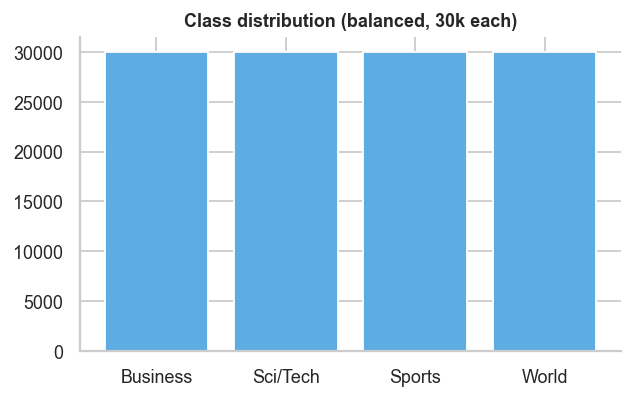

In [17]:
# Class distribution (30k articles per class)
fig, ax = plt.subplots(figsize=(5, 3.2))
vc = df['label'].value_counts()
ax.bar(vc.index, vc.values, color='#5DADE2', edgecolor='white')
ax.set_title('Class distribution (balanced, 30k each)', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig1_classes.png', bbox_inches='tight'); plt.show()

## 2. Text cleaning, tokenisation and dictionary
Cleaning is justified by the corpus: AG News contains HTML entities (`&quot;`->`quot`, `#39`),
agency tags and punctuation. We lowercase, strip non-alphabetic and HTML noise, and drop stopwords,
**news-agency tags (reuters, ap, afp) and date tokens (weekdays, months)** that are extremely frequent
but carry no semantic content, plus tokens shorter than 3 characters. Sentence token-length is
analysed so the chosen window sizes are covered, and the dictionary keeps the **top VOCAB_SIZE** tokens.

Token length: mean=23.2 median=23 max=98


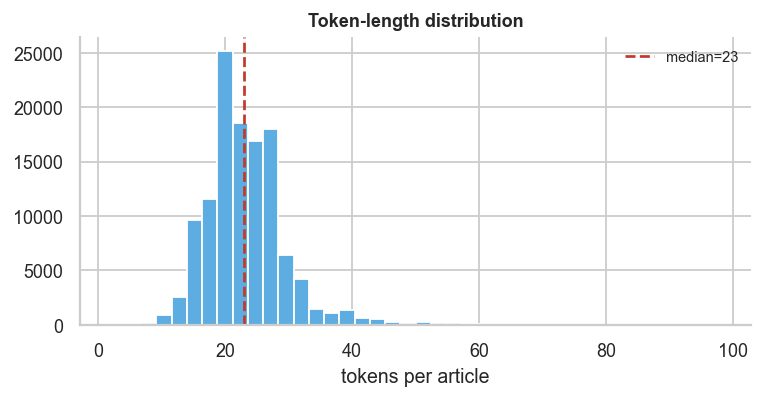

In [18]:
# Clean and tokenise; analyse sentence length so the window sizes are covered
STOP = set(("the a an and or to of in for on at by with from is are was were be been being this that these those "
            "it its as has have had he she they we you i his her their our your not but if then than so over after about "
            "into out up down one two will would can could said more most other new "
            # news-agency tags, weekdays, months and generic time/filler tokens (no semantic content)
            "reuters ap afp reut monday tuesday wednesday thursday friday saturday sunday "
            "january february march april june july august september october november december "
            "first last says year update against who three four five six seven eight nine ten "
            "yesterday today tomorrow week weeks day days month months inc corp ltd also may "
            "time when where what how why").split())

def clean(s):
    """Lowercase, remove HTML/agency/date noise and return meaningful tokens (>2 chars, no stopwords)."""
    s = re.sub(r'&[a-z]+;|quot|#39|lt|gt', ' ', str(s).lower())
    return [w for w in re.findall(r'[a-z]+', s) if len(w) > 2 and w not in STOP]

df['tokens'] = df['text'].map(clean)
df['ntok']   = df['tokens'].map(len)
print('Token length: mean=%.1f median=%d max=%d' % (df['ntok'].mean(), df['ntok'].median(), df['ntok'].max()))

fig, ax = plt.subplots(figsize=(6, 3.2))
ax.hist(df['ntok'], bins=40, color='#5DADE2', edgecolor='white')
ax.axvline(df['ntok'].median(), color='#c0392b', ls='--', label=f"median={int(df['ntok'].median())}")
ax.set_xlabel('tokens per article'); ax.legend(frameon=False, fontsize=8)
ax.set_title('Token-length distribution', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig2_tokenlen.png', bbox_inches='tight'); plt.show()

### 2.1 The most frequent tokens per class confirm the class names

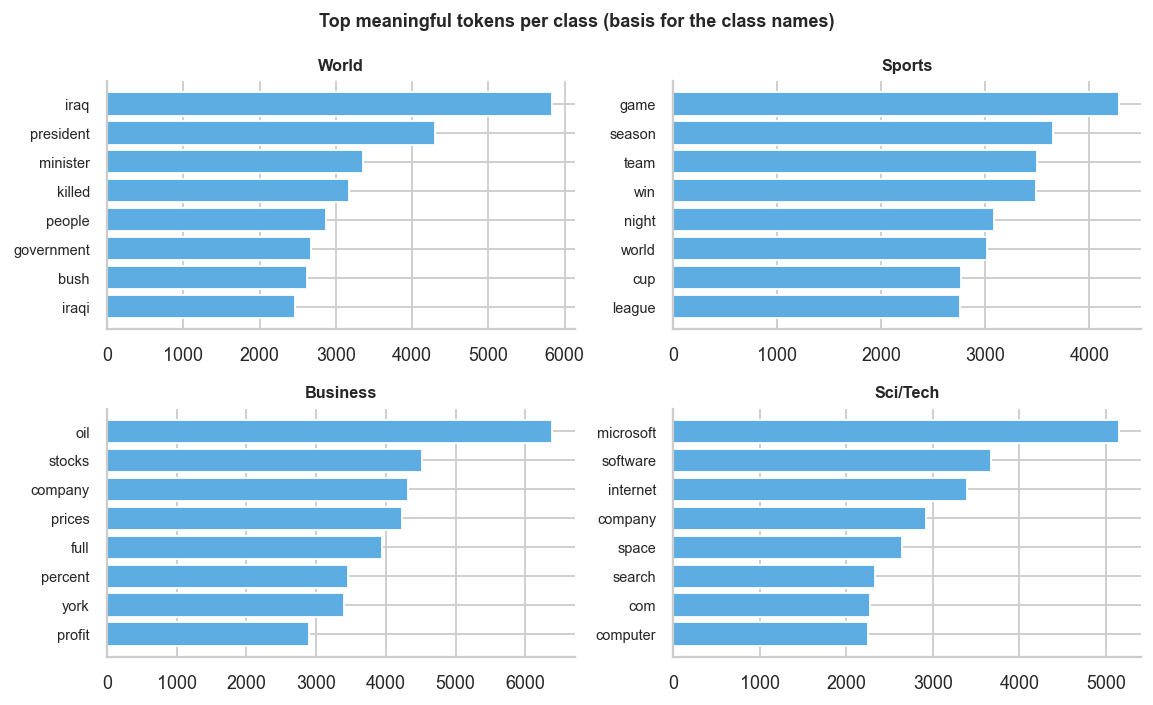

In [19]:
# Most frequent meaningful tokens per class: justifies the class names and shows the text<->target link
topn = 8
fig, axes = plt.subplots(2, 2, figsize=(9, 5.5))
for ax, (ci, name) in zip(axes.ravel(), CLASS_NAMES.items()):
    cnt = collections.Counter(w for toks in df.loc[df['Class Index'] == ci, 'tokens'] for w in toks)
    words, vals = zip(*cnt.most_common(topn))
    ypos = list(range(topn))[::-1]
    ax.barh(ypos, list(vals), color='#5DADE2', edgecolor='white')
    ax.set_yticks(ypos); ax.set_yticklabels(words, fontsize=8)
    ax.set_title(name, fontsize=9, fontweight='bold')
fig.suptitle('Top meaningful tokens per class (basis for the class names)', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig3_topwords.png', bbox_inches='tight'); plt.show()

### 2.2 Dictionary built from the training corpus

In [20]:
# Build the dictionary (vocabulary) from the cleaned tokens
counter  = collections.Counter(w for toks in df['tokens'] for w in toks)
vocab    = [w for w, _ in counter.most_common(VOCAB_SIZE)]
word2idx = {w: i for i, w in enumerate(vocab)}
idx2word = {i: w for w, i in word2idx.items()}
print('Vocabulary size:', len(vocab))

Vocabulary size: 3000


## 3. Word pairs for the Skip-Gram (positive + negative sampling)
Each cleaned sentence yields (target, context) positive pairs within the window (label 1); for every
positive we draw **NEG_SAMPLES random negatives** (label 0). Pairs are built **per window inside the
training loop** and freed afterwards, so the full corpus fits in memory.

In [21]:
# Encode sentences to word ids (in-vocabulary only); pairs are built per window when training
def encode(tokens):
    """Map tokens to their dictionary ids, dropping out-of-vocabulary words."""
    return [word2idx[w] for w in tokens if w in word2idx]

_use = df['tokens'] if N_SENTENCES is None else df['tokens'].head(N_SENTENCES)
sentences = [e for e in (encode(t) for t in _use) if len(e) >= 2]
print(f'Sentences used for pairs: {len(sentences):,}'
      f"{' (FULL corpus)' if N_SENTENCES is None else ''}")

def build_pairs(window):
    """Return target, context and label arrays: positives within the window + NEG_SAMPLES negatives each."""
    pos_t, pos_c = [], []
    for e in sentences:
        L = len(e)
        for i in range(L):
            lo, hi = max(0, i - window), min(L, i + window + 1)
            for j in range(lo, hi):
                if j != i:
                    pos_t.append(e[i]); pos_c.append(e[j])
    pos_t = np.asarray(pos_t, dtype=np.int32); pos_c = np.asarray(pos_c, dtype=np.int32)
    npos = len(pos_t)
    neg_t = np.repeat(pos_t, NEG_SAMPLES)
    neg_c = np.random.randint(0, len(vocab), size=npos * NEG_SAMPLES, dtype=np.int32)
    t = np.concatenate([pos_t, neg_t]); c = np.concatenate([pos_c, neg_c])
    y = np.concatenate([np.ones(npos, np.int8), np.zeros(npos * NEG_SAMPLES, np.int8)])
    return t, c, y

Sentences used for pairs: 119,993 (FULL corpus)


## 4. Skip-Gram model and training of the six embeddings
"One-hot word definition" is realised by an `nn.Embedding` lookup. Target and context embeddings are
combined by a dot product; the loss is **binary cross-entropy** (`BCEWithLogitsLoss`), optimised with **Adam**.

In [22]:
# ============================================================================
# Train six embedding models: {312, 752} x {window 2, 4, 6} on the GPU
# ============================================================================
class SkipGram(nn.Module):
    """Skip-gram with negative sampling: dot(target_emb, context_emb) -> BCEWithLogits."""
    def __init__(self, vocab_size, emb_dim):
        super().__init__()
        self.target  = nn.Embedding(vocab_size, emb_dim)
        self.context = nn.Embedding(vocab_size, emb_dim)
        nn.init.xavier_uniform_(self.target.weight)
        nn.init.xavier_uniform_(self.context.weight)
    def forward(self, t, c):
        return (self.target(t) * self.context(c)).sum(1)

def train_skipgram(t_arr, c_arr, y_arr, emb_dim):
    """Train one Skip-Gram; return the learned target-embedding matrix and the per-epoch loss."""
    model = SkipGram(len(vocab), emb_dim).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.BCEWithLogitsLoss()
    t = torch.from_numpy(t_arr); c = torch.from_numpy(c_arr); y = torch.from_numpy(y_arr).float()
    n = len(t); losses = []
    for ep in range(EPOCHS):
        perm = torch.randperm(n); running = 0.0
        for s in range(0, n, BATCH_SIZE):
            idx = perm[s:s + BATCH_SIZE]
            bt = t[idx].to(DEVICE).long(); bc = c[idx].to(DEVICE).long(); by = y[idx].to(DEVICE)
            opt.zero_grad(); out = model(bt, bc); loss = loss_fn(out, by)
            loss.backward(); opt.step(); running += loss.item() * len(idx)
        losses.append(running / n); print(f'    epoch {ep + 1}/{EPOCHS} loss={losses[-1]:.4f}')
    return model.target.weight.detach().cpu().numpy(), losses

embeddings = {}; histories = {}
total = len(EMB_DIMS) * len(WINDOWS); n_done = 0
for win in WINDOWS:
    print(f'\n=== window {win}: building pairs ===')
    t_arr, c_arr, y_arr = build_pairs(win)
    print(f'window={win}: {len(t_arr):,} rows ({(y_arr == 1).mean() * 100:.0f}% positive, {NEG_SAMPLES} neg/pos)')
    for dim in EMB_DIMS:
        n_done += 1; key = f'd{dim}_w{win}'
        print(f'[{n_done}/{total}] training {key} ...')
        embeddings[key], histories[key] = train_skipgram(t_arr, c_arr, y_arr, dim)
    del t_arr, c_arr, y_arr


=== window 2: building pairs ===
window=2: 43,876,476 rows (17% positive, 5 neg/pos)
[1/6] training d312_w2 ...
    epoch 1/10 loss=0.3321
    epoch 2/10 loss=0.3036
    epoch 3/10 loss=0.2960
    epoch 4/10 loss=0.2924
    epoch 5/10 loss=0.2904
    epoch 6/10 loss=0.2891
    epoch 7/10 loss=0.2882
    epoch 8/10 loss=0.2876
    epoch 9/10 loss=0.2871
    epoch 10/10 loss=0.2867
[2/6] training d752_w2 ...
    epoch 1/10 loss=0.3276
    epoch 2/10 loss=0.2995
    epoch 3/10 loss=0.2909
    epoch 4/10 loss=0.2863
    epoch 5/10 loss=0.2837
    epoch 6/10 loss=0.2821
    epoch 7/10 loss=0.2811
    epoch 8/10 loss=0.2804
    epoch 9/10 loss=0.2799
    epoch 10/10 loss=0.2795

=== window 4: building pairs ===
window=4: 81,995,340 rows (17% positive, 5 neg/pos)
[3/6] training d312_w4 ...
    epoch 1/10 loss=0.3357
    epoch 2/10 loss=0.3192
    epoch 3/10 loss=0.3161
    epoch 4/10 loss=0.3148
    epoch 5/10 loss=0.3142
    epoch 6/10 loss=0.3138
    epoch 7/10 loss=0.3135
    epoch 8/10 l

### 4.1 Training loss converges for every embedding

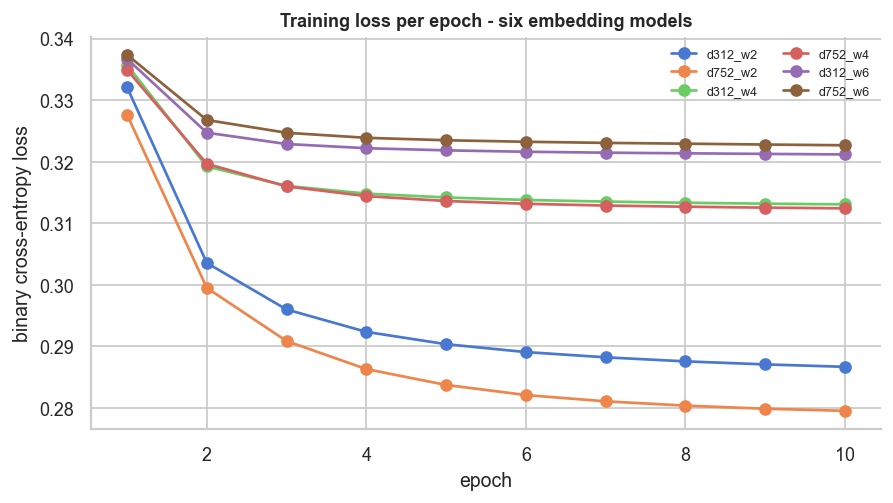

In [23]:
# Binary cross-entropy loss per epoch for the six embedding networks
fig, ax = plt.subplots(figsize=(7, 4))
for key, loss in histories.items():
    ax.plot(range(1, len(loss) + 1), loss, marker='o', label=key)
ax.set_xlabel('epoch'); ax.set_ylabel('binary cross-entropy loss')
ax.legend(fontsize=7, ncol=2, frameon=False)
ax.set_title('Training loss per epoch - six embedding models', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig4_embed_loss.png', bbox_inches='tight'); plt.show()

## 5. Embedding evaluation with cosine distance

In [24]:
# Cosine helpers (numpy, no extra dependencies)
def _norm(M):
    return M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-9)

def cosine_matrix(M):
    """Pairwise cosine similarity matrix for the rows of M."""
    Mn = _norm(M); return Mn @ Mn.T

### 5.1 Ten most frequent meaningful words

Table 1. Ten most frequent meaningful words and their corpus frequency
     word  frequency
    world       8634
  company       7656
      oil       7564
     iraq       6335
     york       6268
president       5994
microsoft       5936
  million       5812
     game       5774
   united       5129


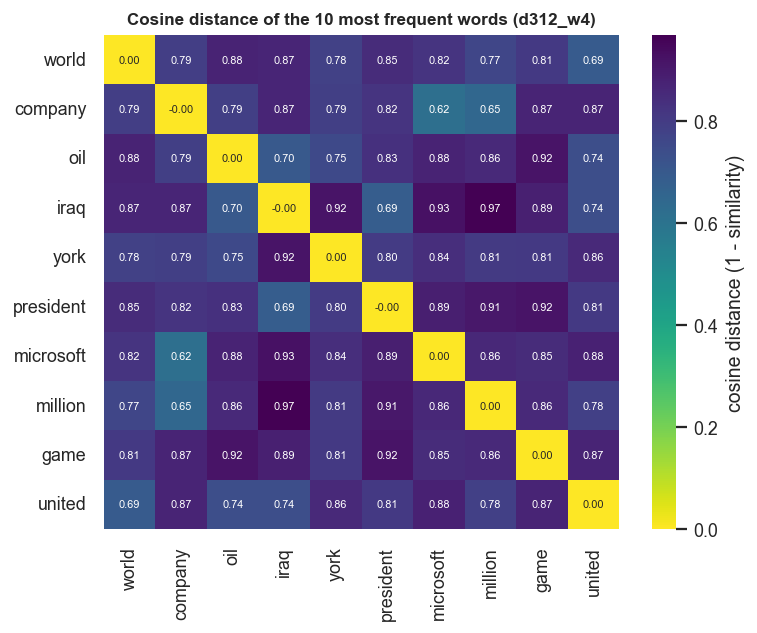

In [25]:
# Table 1 - the ten most frequent meaningful words and their frequency
top10_counts = counter.most_common(10)
top10 = [w for w, _ in top10_counts]
freq_table = pd.DataFrame(top10_counts, columns=['word', 'frequency'])
print('Table 1. Ten most frequent meaningful words and their corpus frequency')
print(freq_table.to_string(index=False))

# Cosine distance (= 1 - cosine similarity) among them, for one reference embedding
ref = 'd312_w4'; E = embeddings[ref]; idx = [word2idx[w] for w in top10]
dist = 1 - cosine_matrix(E[idx])
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(dist, xticklabels=top10, yticklabels=top10, cmap='viridis_r', annot=True, fmt='.2f',
            annot_kws={'size': 6}, cbar_kws={'label': 'cosine distance (1 - similarity)'}, ax=ax)
ax.set_title(f'Cosine distance of the 10 most frequent words ({ref})', fontsize=9.5, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig5_top10_cosine.png', bbox_inches='tight'); plt.show()

### 5.2 Five semantic groups: cosine distance by window and embedding size

Table 2. Average intra-group cosine DISTANCE by embedding size (dim) and window:
dim          312                  752              
window         2      4      6      2      4      6
group                                              
finance    0.618  0.561  0.531  0.653  0.598  0.572
geography  0.872  0.872  0.890  0.874  0.890  0.884
politics   0.720  0.646  0.647  0.788  0.710  0.714
sports     0.648  0.556  0.573  0.719  0.671  0.640
tech       0.700  0.660  0.647  0.764  0.723  0.715


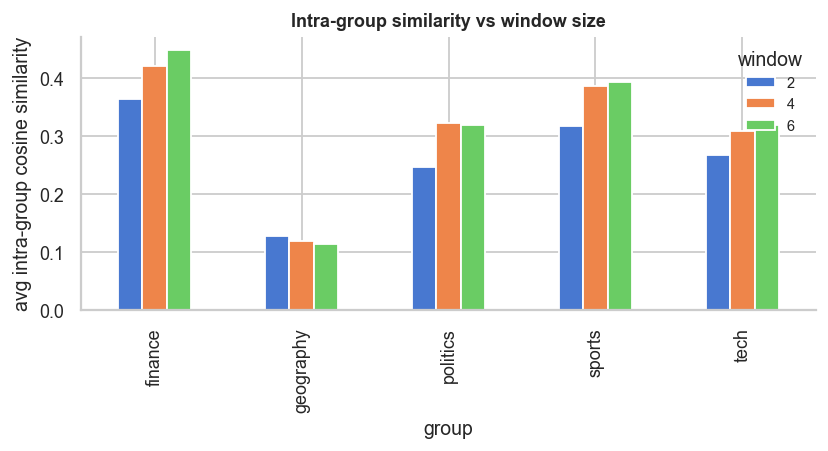

In [26]:
# Five semantic groups (>=3 words each) -> cosine distance across window sizes AND embedding sizes
groups = {
 'politics':  ['president', 'government', 'minister', 'war'],
 'sports':    ['game', 'team', 'season', 'league'],
 'finance':   ['oil', 'stocks', 'prices', 'percent'],
 'tech':      ['software', 'internet', 'computer', 'security'],
 'geography': ['york', 'iraq', 'china', 'europe']}

rows = []
for dim in EMB_DIMS:
    for win in WINDOWS:
        E = embeddings[f'd{dim}_w{win}']
        for g, words in groups.items():
            ids = [word2idx[w] for w in words if w in word2idx]
            if len(ids) >= 2:
                s = cosine_matrix(E[ids]); m = (s.sum() - len(ids)) / (len(ids) * (len(ids) - 1))
                rows.append({'dim': dim, 'window': win, 'group': g,
                             'avg_cosine_sim':  round(float(m), 3),
                             'avg_cosine_dist': round(1 - float(m), 3)})
gdf = pd.DataFrame(rows)
print('Table 2. Average intra-group cosine DISTANCE by embedding size (dim) and window:')
print(gdf.pivot_table(index='group', columns=['dim', 'window'], values='avg_cosine_dist').round(3).to_string())

# Window sensitivity (averaged over embedding size)
piv = gdf.pivot_table(index='group', columns='window', values='avg_cosine_sim', aggfunc='mean')
fig, ax = plt.subplots(figsize=(6.5, 3.6)); piv.plot.bar(ax=ax)
ax.set_ylabel('avg intra-group cosine similarity')
ax.set_title('Intra-group similarity vs window size', fontsize=10, fontweight='bold')
ax.legend(title='window', fontsize=8, frameon=False)
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig6_groups.png', bbox_inches='tight'); plt.show()

### 5.3 Quantitative embedding quality: class-separation score
Nearest neighbours are only a qualitative check. As an **objective, quantitative** metric we measure
how well each embedding **separates the four news classes**: every dictionary word is auto-labelled by
its dominant class (>=50% of its occurrences, >=20 total) and we compute a **cosine silhouette** of
those words against the class centroids (higher = same-topic words together, different topics apart).
The embedding never saw the class labels, so this is a genuine intrinsic test. The downstream
classifier in Part 2 (test-set accuracy/F1) is the complementary **extrinsic** measure.

Class-leaning words used for the score: 1818

Table 3. Class-separation silhouette per embedding (intrinsic quality, higher = better):
d312_w6    0.1438
d312_w4    0.1343
d752_w6    0.1186
d312_w2    0.1174
d752_w4    0.1073
d752_w2    0.0942

Intra-group cosine ranking (secondary):
dim  window
312  6         0.342
     4         0.341
752  6         0.295
312  2         0.288
752  4         0.282
     2         0.240

Best embedding (class separation): d312_w6 = 0.1438


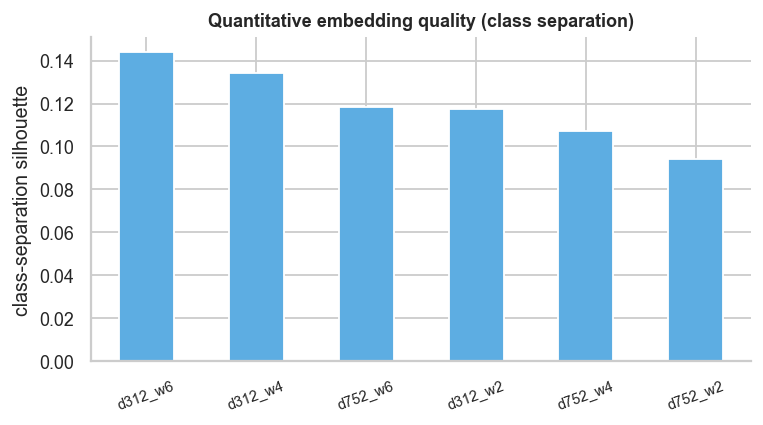

In [27]:
# Intrinsic quality metric: class-separation silhouette (objective, uses all class-leaning words)
cls_count = {c: collections.Counter() for c in CLASS_NAMES}
for ci, toks in zip(df['Class Index'], df['tokens']):
    for w in toks:
        if w in word2idx: cls_count[ci][w] += 1
labels = {}
for w in vocab:
    tot = sum(cls_count[c][w] for c in CLASS_NAMES)
    if tot >= 20:
        share = {c: cls_count[c][w] / tot for c in CLASS_NAMES}
        c_best = max(share, key=share.get)
        if share[c_best] >= 0.5: labels[w] = c_best
print(f'Class-leaning words used for the score: {len(labels)}')

def class_separation(E):
    """Mean cosine silhouette of class-leaning words against class centroids (higher = better)."""
    En = _norm(E)
    cents = {c: _norm(En[[word2idx[w] for w, l in labels.items() if l == c]].mean(0, keepdims=True))[0]
             for c in CLASS_NAMES}
    sil = []
    for w, l in labels.items():
        v = En[word2idx[w]]
        a = float(v @ cents[l]); b = max(float(v @ cents[c]) for c in CLASS_NAMES if c != l)
        sil.append(a - b)
    return float(np.mean(sil))

sep = pd.Series({k: round(class_separation(embeddings[k]), 4) for k in embeddings}).sort_values(ascending=False)
rank = gdf.groupby(['dim', 'window'])['avg_cosine_sim'].mean().sort_values(ascending=False).round(3)
print('\nTable 3. Class-separation silhouette per embedding (intrinsic quality, higher = better):')
print(sep.to_string())
print('\nIntra-group cosine ranking (secondary):'); print(rank.to_string())
print(f'\nBest embedding (class separation): {sep.index[0]} = {sep.iloc[0]}')

fig, ax = plt.subplots(figsize=(6, 3.4))
sep.plot.bar(ax=ax, color='#5DADE2', edgecolor='white')
ax.set_ylabel('class-separation silhouette'); ax.set_xticklabels(sep.index, rotation=20, fontsize=8)
ax.set_title('Quantitative embedding quality (class separation)', fontsize=10, fontweight='bold')
plt.tight_layout(); plt.savefig(FIGURES_DIR / 'fig7_separation.png', bbox_inches='tight'); plt.show()

### 5.4 Summary
- **Ten most frequent meaningful words**: Table 1 + the cosine-distance matrix. Stopwords, agency tags
  and date tokens are excluded so every listed token carries meaning.
- **Semantic groups + cosine distance**: Table 2 (distance per `dim x window`); the bar chart
  summarises the window effect.
  - *Sensitivity to window size*: larger windows -> higher intra-group similarity (lower distance).
  - *Group cohesion*: per-group distances in Table 2 (lower = tighter group).
- **Interpretability/stability**: Table 3 (class-separation silhouette) ranks the six embeddings by a
  single quantitative metric and names the best.

**The embeddings used by the classifier (Part 2) are saved below** (no external/pretrained vectors).

## 6. Save the embeddings for the classifier

In [28]:
# Persist every embedding matrix + the vocabulary; the classification notebook loads this file
np.savez('embeddings_MLR.npz', vocab=np.array(vocab),
         **{k: v for k, v in embeddings.items()})
print('Saved embeddings_MLR.npz with:', list(embeddings.keys()))

Saved embeddings_MLR.npz with: ['d312_w2', 'd752_w2', 'd312_w4', 'd752_w4', 'd312_w6', 'd752_w6']
